CUDA unavailable; using CPU.


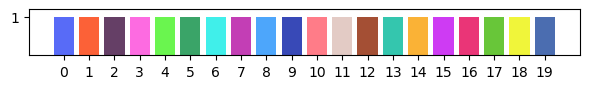

In [2]:
import glob, re, joblib
import numpy as np
import scanpy as sc
import seaborn as sns
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import string
import pyarrow.parquet as pq
import matplotlib.patches as mpatches
from Utils import colors_to_use, colors_to_use_pastel
import math
#from matplotlib.backends.backend_pdf import PdfPages
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu
from XplainTDA_PH import XplainTDA
N = len(colors_to_use)

plt.figure(figsize=(6, 1))

plt.bar(
    range(N),
    [1] * N,
    color=colors_to_use
)

plt.xticks(range(N))
plt.yticks([1])
plt.ylim(0, 1.2)

plt.tight_layout()
plt.show()

# SuppFig1

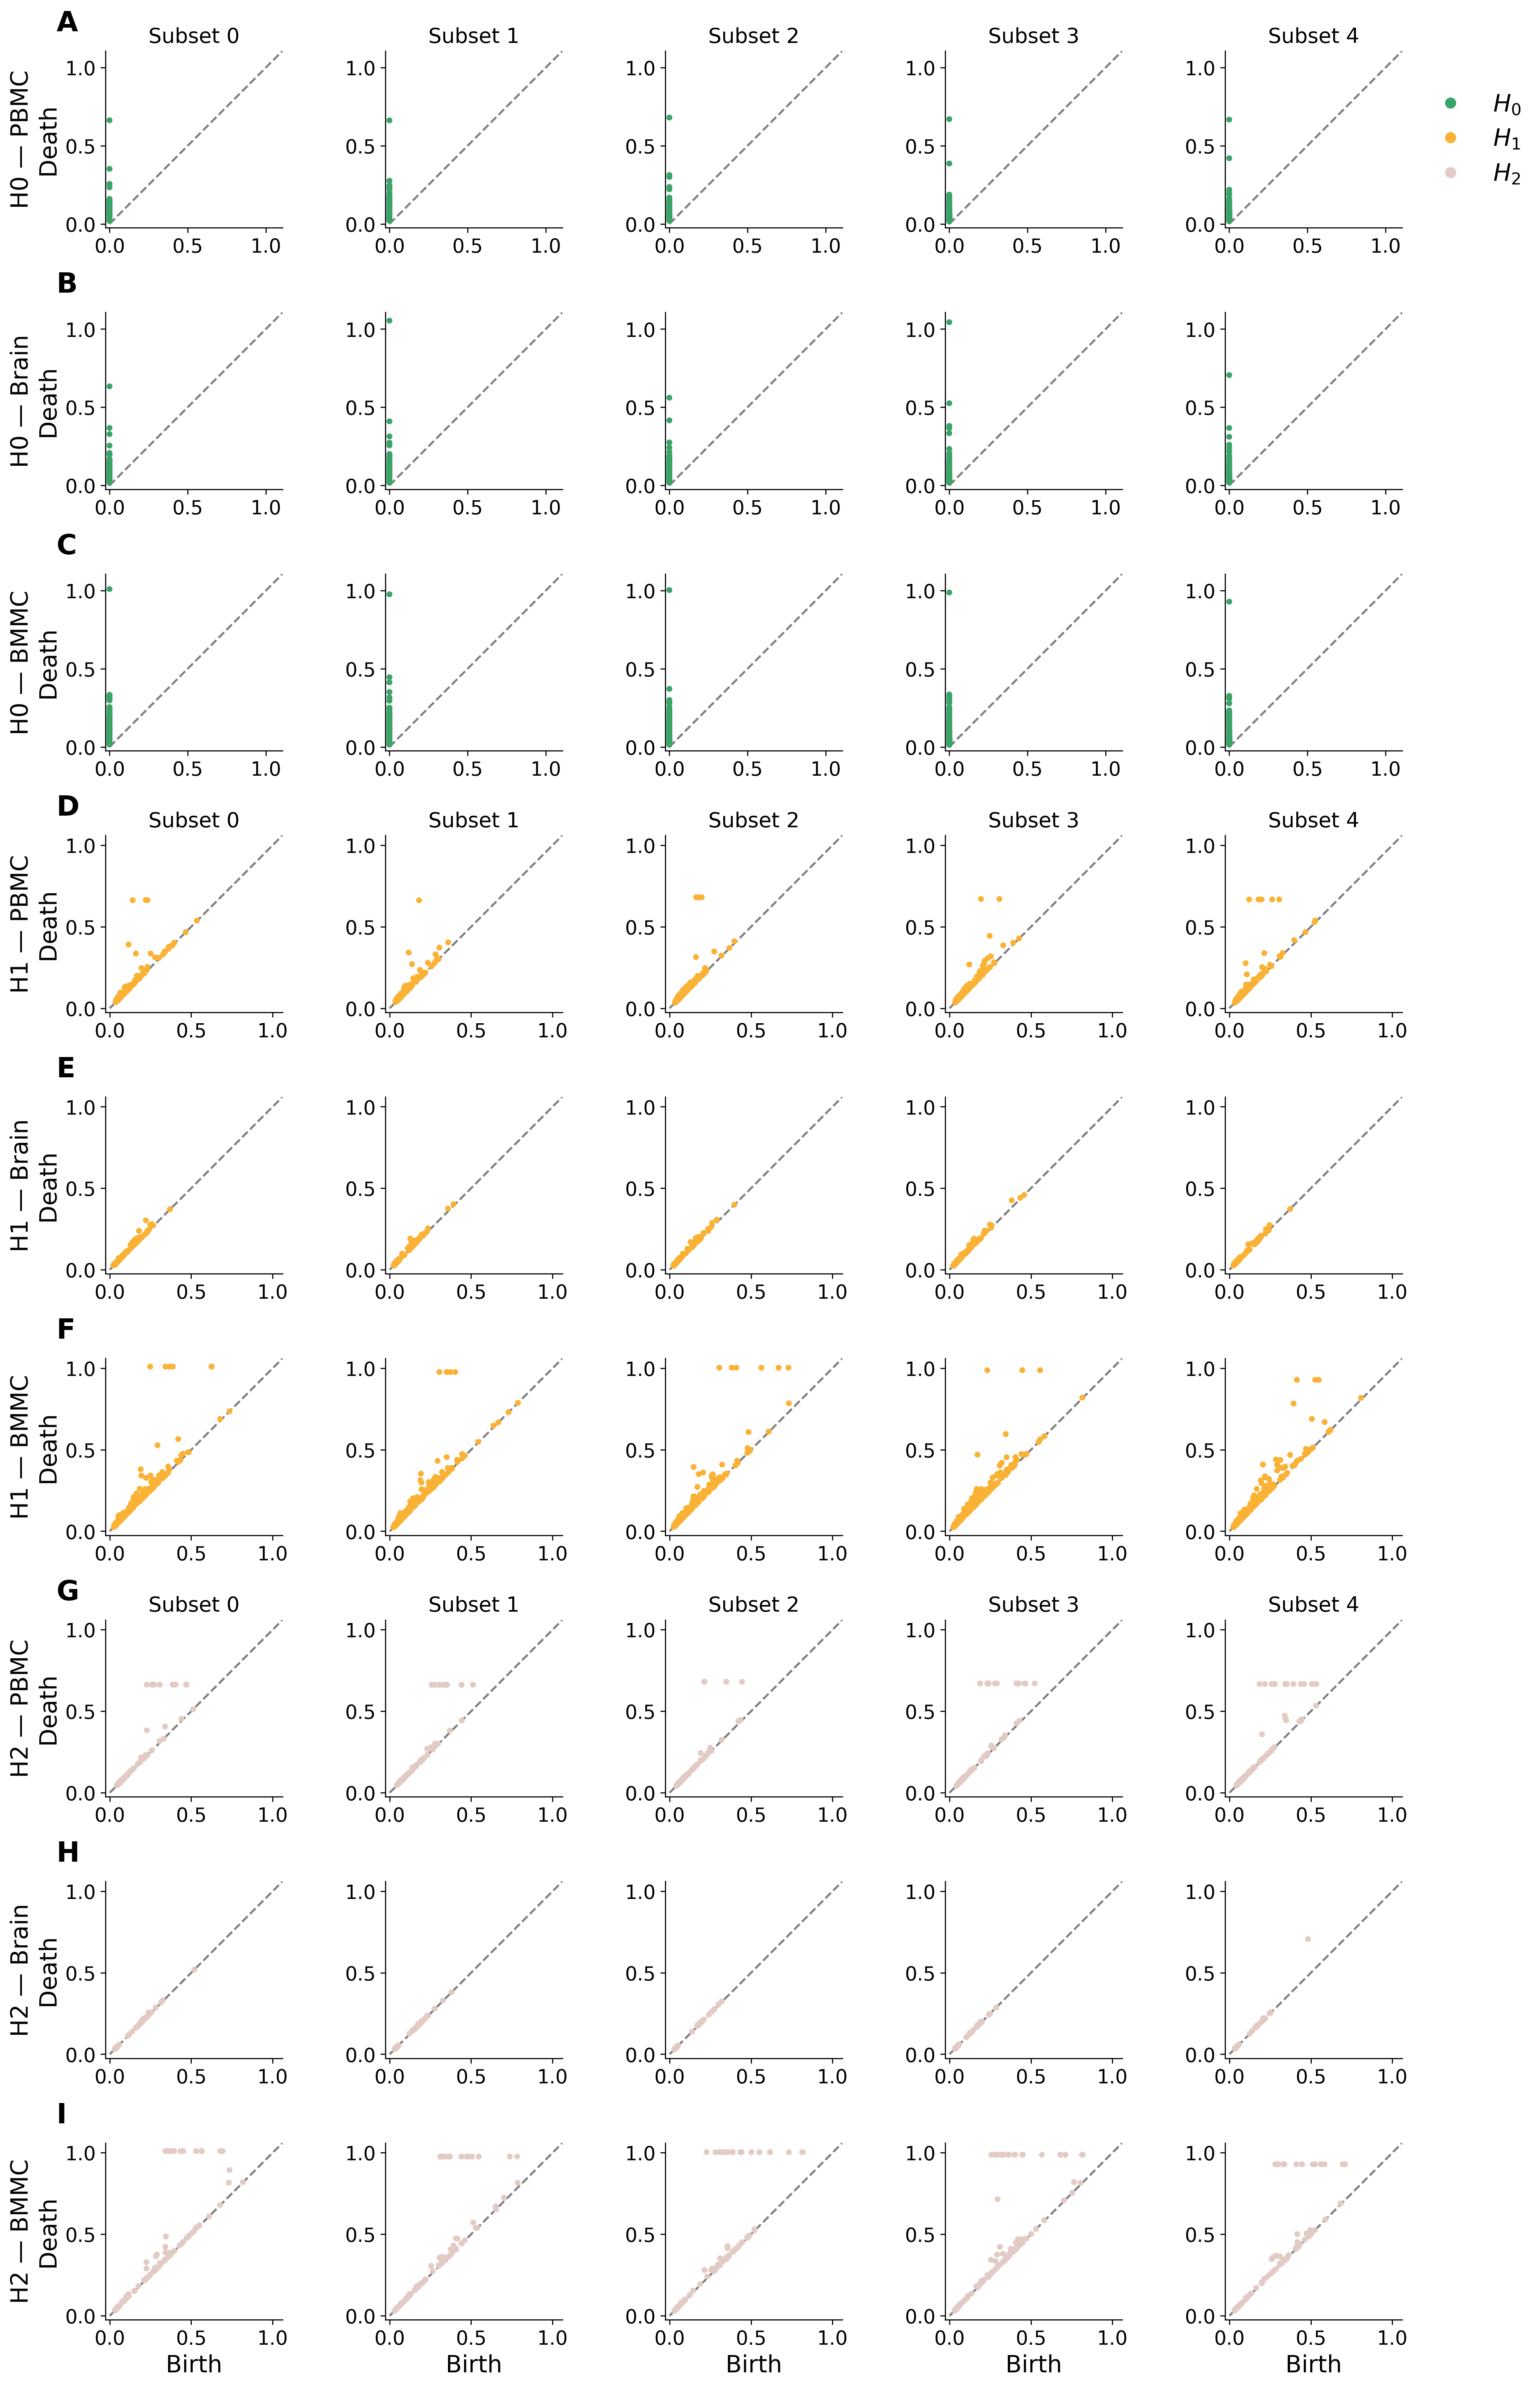

In [5]:
# --------------------------------------------------
# Settings / style
# --------------------------------------------------
datasets_aliases = {
    "PBMC": "PBMC",
    "HumanBrain": "Brain",
    "BMMCMultiOme": "BMMC",
}
datasets = list(datasets_aliases)
omic = "GEX"
n_subsets = 5

homology_palette = {
    "H0": colors_to_use[5],
    "H1": colors_to_use[14],
    "H2": colors_to_use[11],
}

plt.rcParams.update({
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "lines.linewidth": 3,
    "figure.dpi": 300,
})


# --------------------------------------------------
# Load TDA objects
# --------------------------------------------------
tdas = {
    dataset: [
        XplainTDA.load(
            Path("Datasets") / dataset / "XplainTDA" / omic / "Stability" / "GRAE"
            / "Subsampling" / "subsets" / f"subset_{i}" / f"tda_subset_{i}.joblib"
        )
        for i in range(n_subsets)
    ]
    for dataset in datasets
}

# finite diagrams only
dgms = {
    dataset: {
        dim: [
            np.asarray(tda.dgms[dim])[np.isfinite(np.asarray(tda.dgms[dim])).all(axis=1)]
            for tda in tdas[dataset]
        ]
        for dim in range(3)
    }
    for dataset in datasets
}

# one common limit per homology dimension across all datasets/subsets
lims = {
    dim: 1.05 * max(
        (
            d.max()
            for dataset in datasets
            for d in dgms[dataset][dim]
            if len(d)
        ),
        default=1.0,
    )
    for dim in range(3)
}


# --------------------------------------------------
# Plot: 9 rows x 5 columns
# rows 0-2 = H0, rows 3-5 = H1, rows 6-8 = H2
# --------------------------------------------------
n_rows = 3 * len(datasets)
fig, axes = plt.subplots(n_rows, n_subsets, figsize=(16, 24))

for dim in range(3):
    color = homology_palette[f"H{dim}"]
    lim = lims[dim]

    for row, dataset in enumerate(datasets):
        grid_row = dim * len(datasets) + row

        for subset_id in range(n_subsets):
            ax = axes[grid_row, subset_id]
            dgm = dgms[dataset][dim][subset_id]

            if len(dgm):
                ax.scatter(
                    dgm[:, 0], dgm[:, 1],
                    s=18, color=color, edgecolor="none"
                )

            ax.plot([0, lim], [0, lim], "--", color="grey", lw=1.5, zorder=0)
            ax.set(xlim=(-.025, lim), ylim=(-.025, lim), aspect="equal")
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(False)

            # titles only on first row of each H block
            if row == 0:
                ax.set_title(f"Subset {subset_id}", fontsize=15, pad=6)

            # x label only on bottom row of whole figure
            ax.set_xlabel("Birth" if grid_row == n_rows - 1 else "")

            # y label only on first column
            if subset_id == 0:
                ax.set_ylabel(f"H{dim} — {datasets_aliases[dataset]}\nDeath")
            else:
                ax.set_ylabel("")

            # panel letters on first column
            if subset_id == 0:
                ax.text(
                    -0.28, 1.08,
                    rf"$\mathbf{{{string.ascii_uppercase[grid_row]}}}$",
                    transform=ax.transAxes,
                    fontsize=20,
                    va="bottom",
                    ha="left",
                )

# legend
handles = [
    Line2D(
        [0], [0], marker="o", linestyle="", markersize=8,
        markerfacecolor=homology_palette[f"H{dim}"],
        markeredgecolor="none", label=rf"$H_{dim}$"
    )
    for dim in range(3)
]

axes[0, -1].legend(
    handles=handles,
    bbox_to_anchor=(1.02, .5),
    loc="center left",
    fontsize=17,
    title_fontsize=20,
    frameon=False,
)

plt.tight_layout()
fig.savefig(
    f"Figures/XplainTDA_SuppFig1.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.3,
)
plt.show()

# SuppFig2

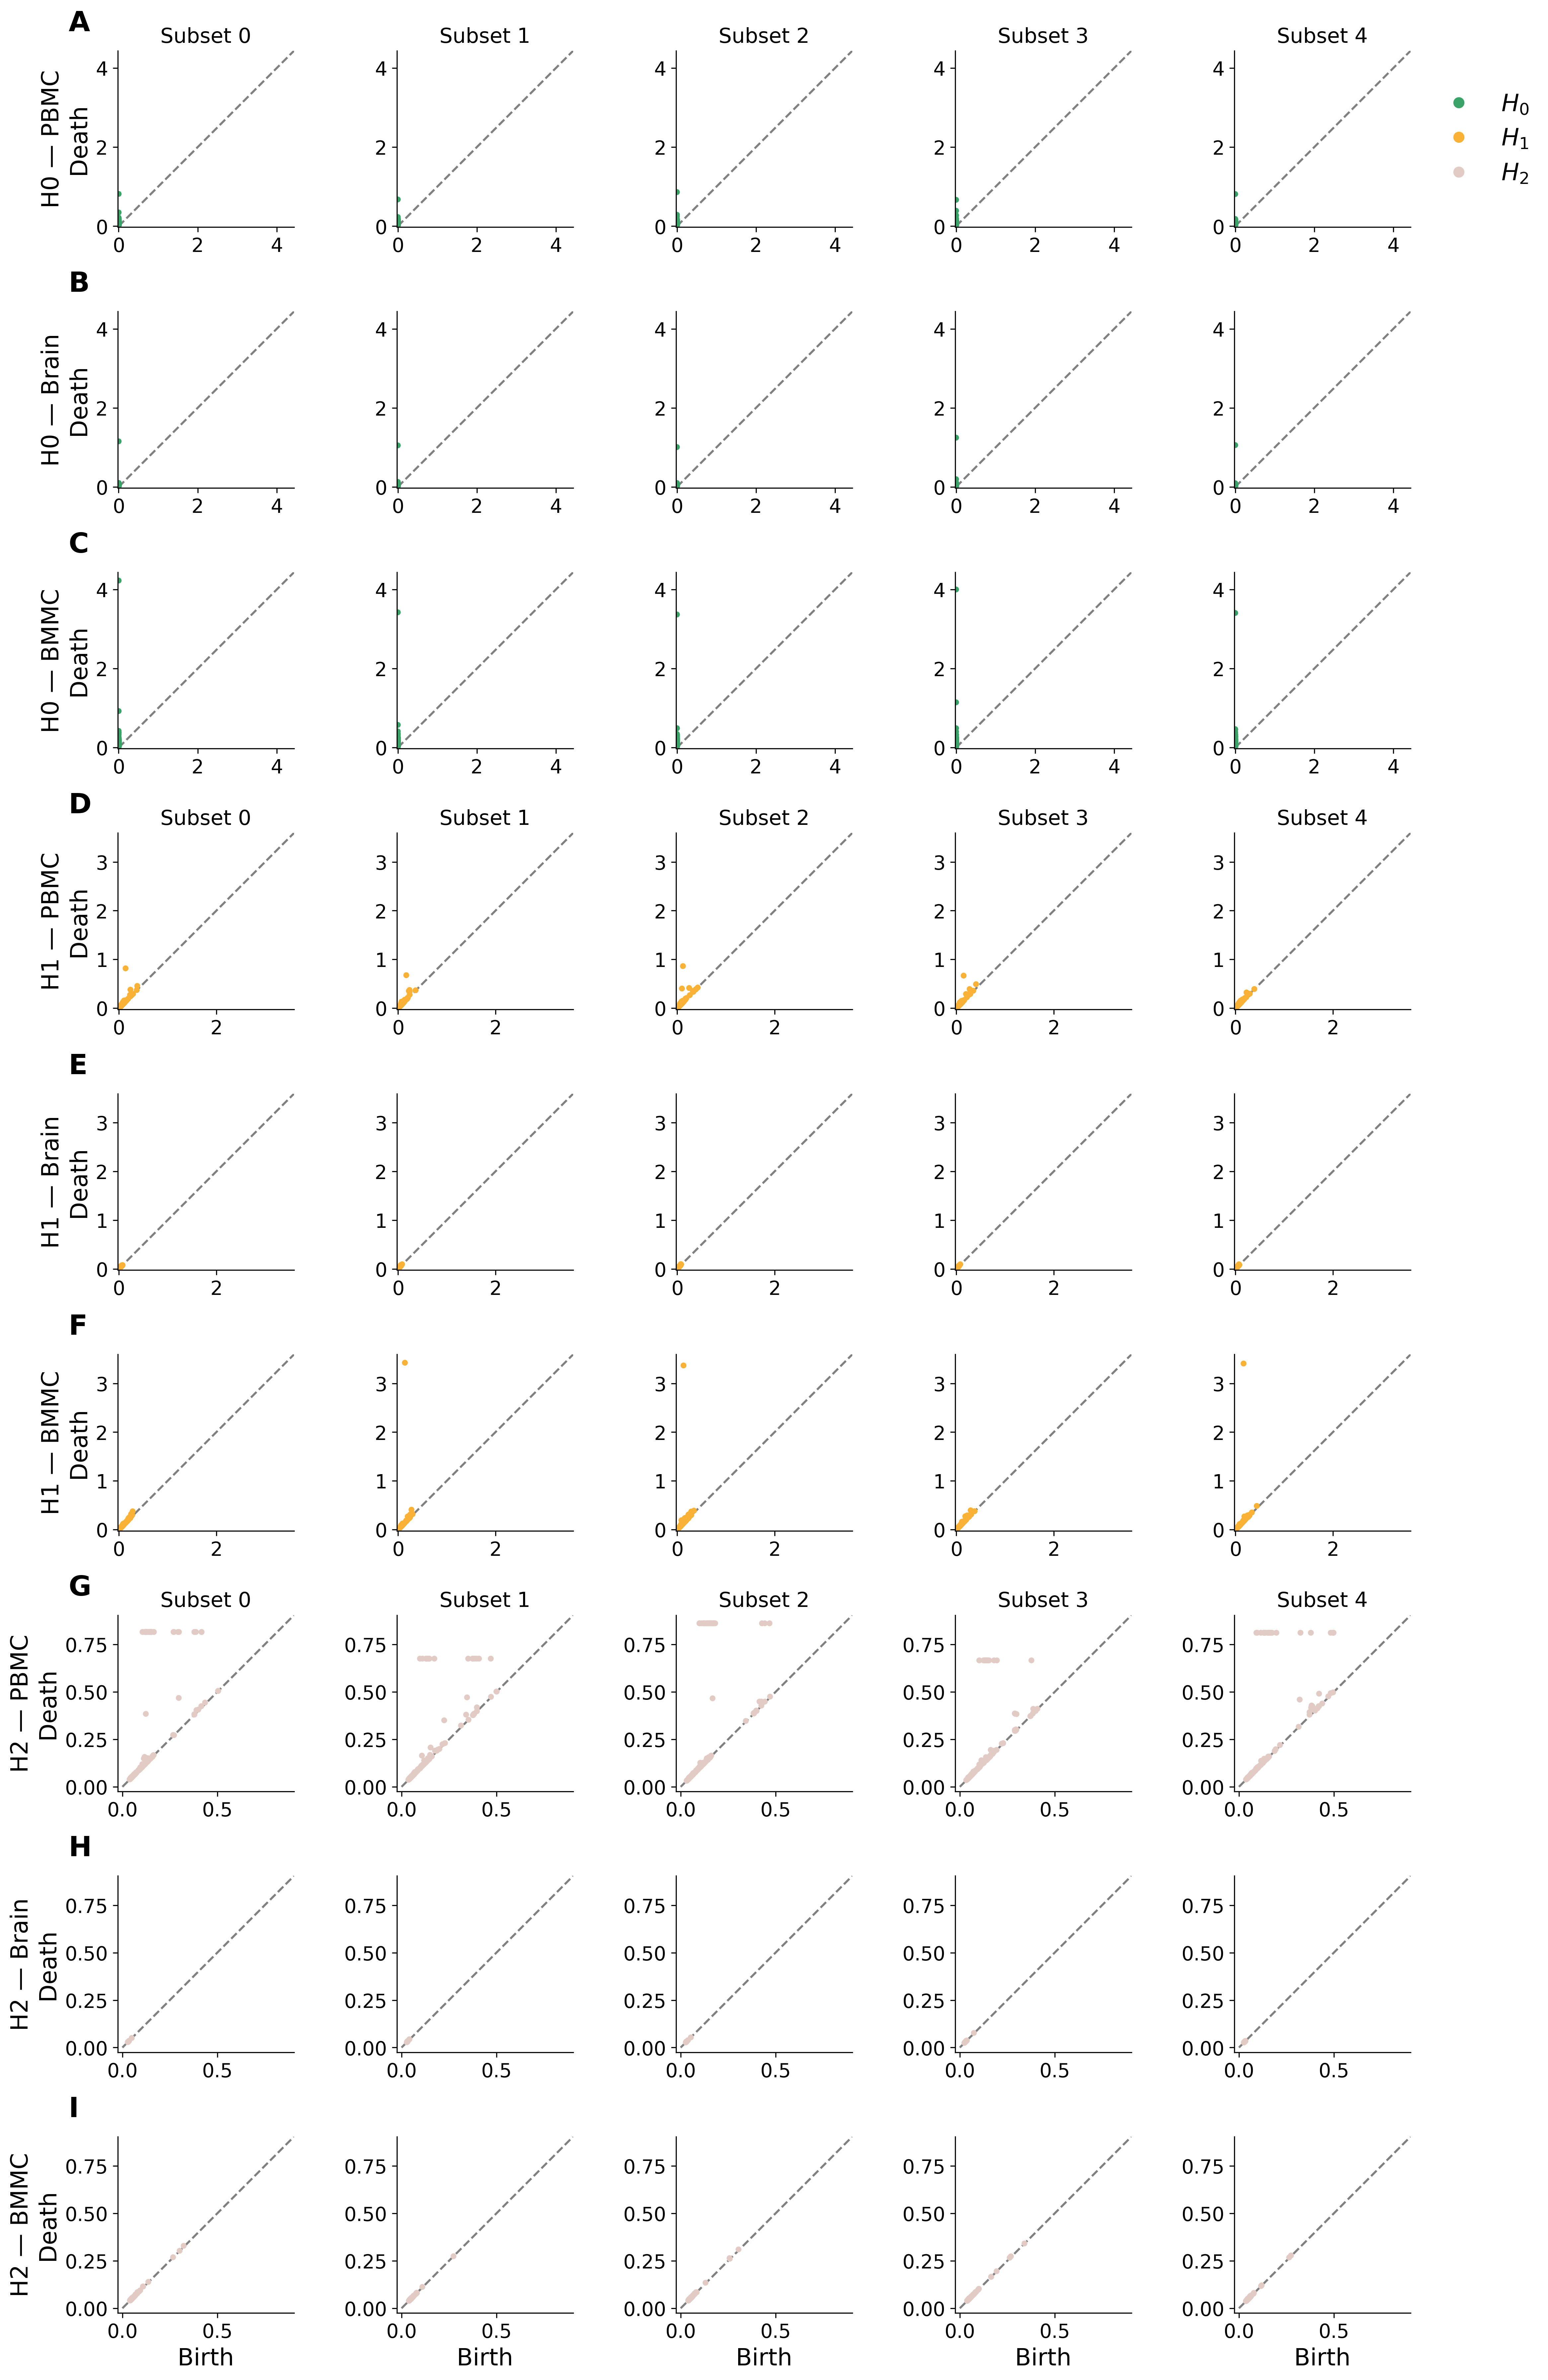

In [6]:
# --------------------------------------------------
# Settings / style
# --------------------------------------------------
datasets_aliases = {
    "PBMC": "PBMC",
    "HumanBrain": "Brain",
    "BMMCMultiOme": "BMMC",
}
datasets = list(datasets_aliases)
omic = "Peak"
n_subsets = 5

homology_palette = {
    "H0": colors_to_use[5],
    "H1": colors_to_use[14],
    "H2": colors_to_use[11],
}

plt.rcParams.update({
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "lines.linewidth": 3,
    "figure.dpi": 300,
})


# --------------------------------------------------
# Load TDA objects
# --------------------------------------------------
tdas = {
    dataset: [
        XplainTDA.load(
            Path("Datasets") / dataset / "XplainTDA" / omic / "Stability" / "GRAE"
            / "Subsampling" / "subsets" / f"subset_{i}" / f"tda_subset_{i}.joblib"
        )
        for i in range(n_subsets)
    ]
    for dataset in datasets
}

# finite diagrams only
dgms = {
    dataset: {
        dim: [
            np.asarray(tda.dgms[dim])[np.isfinite(np.asarray(tda.dgms[dim])).all(axis=1)]
            for tda in tdas[dataset]
        ]
        for dim in range(3)
    }
    for dataset in datasets
}

# one common limit per homology dimension across all datasets/subsets
lims = {
    dim: 1.05 * max(
        (
            d.max()
            for dataset in datasets
            for d in dgms[dataset][dim]
            if len(d)
        ),
        default=1.0,
    )
    for dim in range(3)
}


# --------------------------------------------------
# Plot: 9 rows x 5 columns
# rows 0-2 = H0, rows 3-5 = H1, rows 6-8 = H2
# --------------------------------------------------
n_rows = 3 * len(datasets)
fig, axes = plt.subplots(n_rows, n_subsets, figsize=(16, 24))

for dim in range(3):
    color = homology_palette[f"H{dim}"]
    lim = lims[dim]

    for row, dataset in enumerate(datasets):
        grid_row = dim * len(datasets) + row

        for subset_id in range(n_subsets):
            ax = axes[grid_row, subset_id]
            dgm = dgms[dataset][dim][subset_id]

            if len(dgm):
                ax.scatter(
                    dgm[:, 0], dgm[:, 1],
                    s=18, color=color, edgecolor="none"
                )

            ax.plot([0, lim], [0, lim], "--", color="grey", lw=1.5, zorder=0)
            ax.set(xlim=(-.025, lim), ylim=(-.025, lim), aspect="equal")
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(False)

            # titles only on first row of each H block
            if row == 0:
                ax.set_title(f"Subset {subset_id}", fontsize=15, pad=6)

            # x label only on bottom row of whole figure
            ax.set_xlabel("Birth" if grid_row == n_rows - 1 else "")

            # y label only on first column
            if subset_id == 0:
                ax.set_ylabel(f"H{dim} — {datasets_aliases[dataset]}\nDeath")
            else:
                ax.set_ylabel("")

            # panel letters on first column
            if subset_id == 0:
                ax.text(
                    -0.28, 1.08,
                    rf"$\mathbf{{{string.ascii_uppercase[grid_row]}}}$",
                    transform=ax.transAxes,
                    fontsize=20,
                    va="bottom",
                    ha="left",
                )

# legend
handles = [
    Line2D(
        [0], [0], marker="o", linestyle="", markersize=8,
        markerfacecolor=homology_palette[f"H{dim}"],
        markeredgecolor="none", label=rf"$H_{dim}$"
    )
    for dim in range(3)
]

axes[0, -1].legend(
    handles=handles,
    bbox_to_anchor=(1.02, .5),
    loc="center left",
    fontsize=17,
    title_fontsize=20,
    frameon=False,
)

plt.tight_layout()
fig.savefig(
    f"Figures/XplainTDA_SuppFig2.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.3,
)
plt.show()

# Figure 1

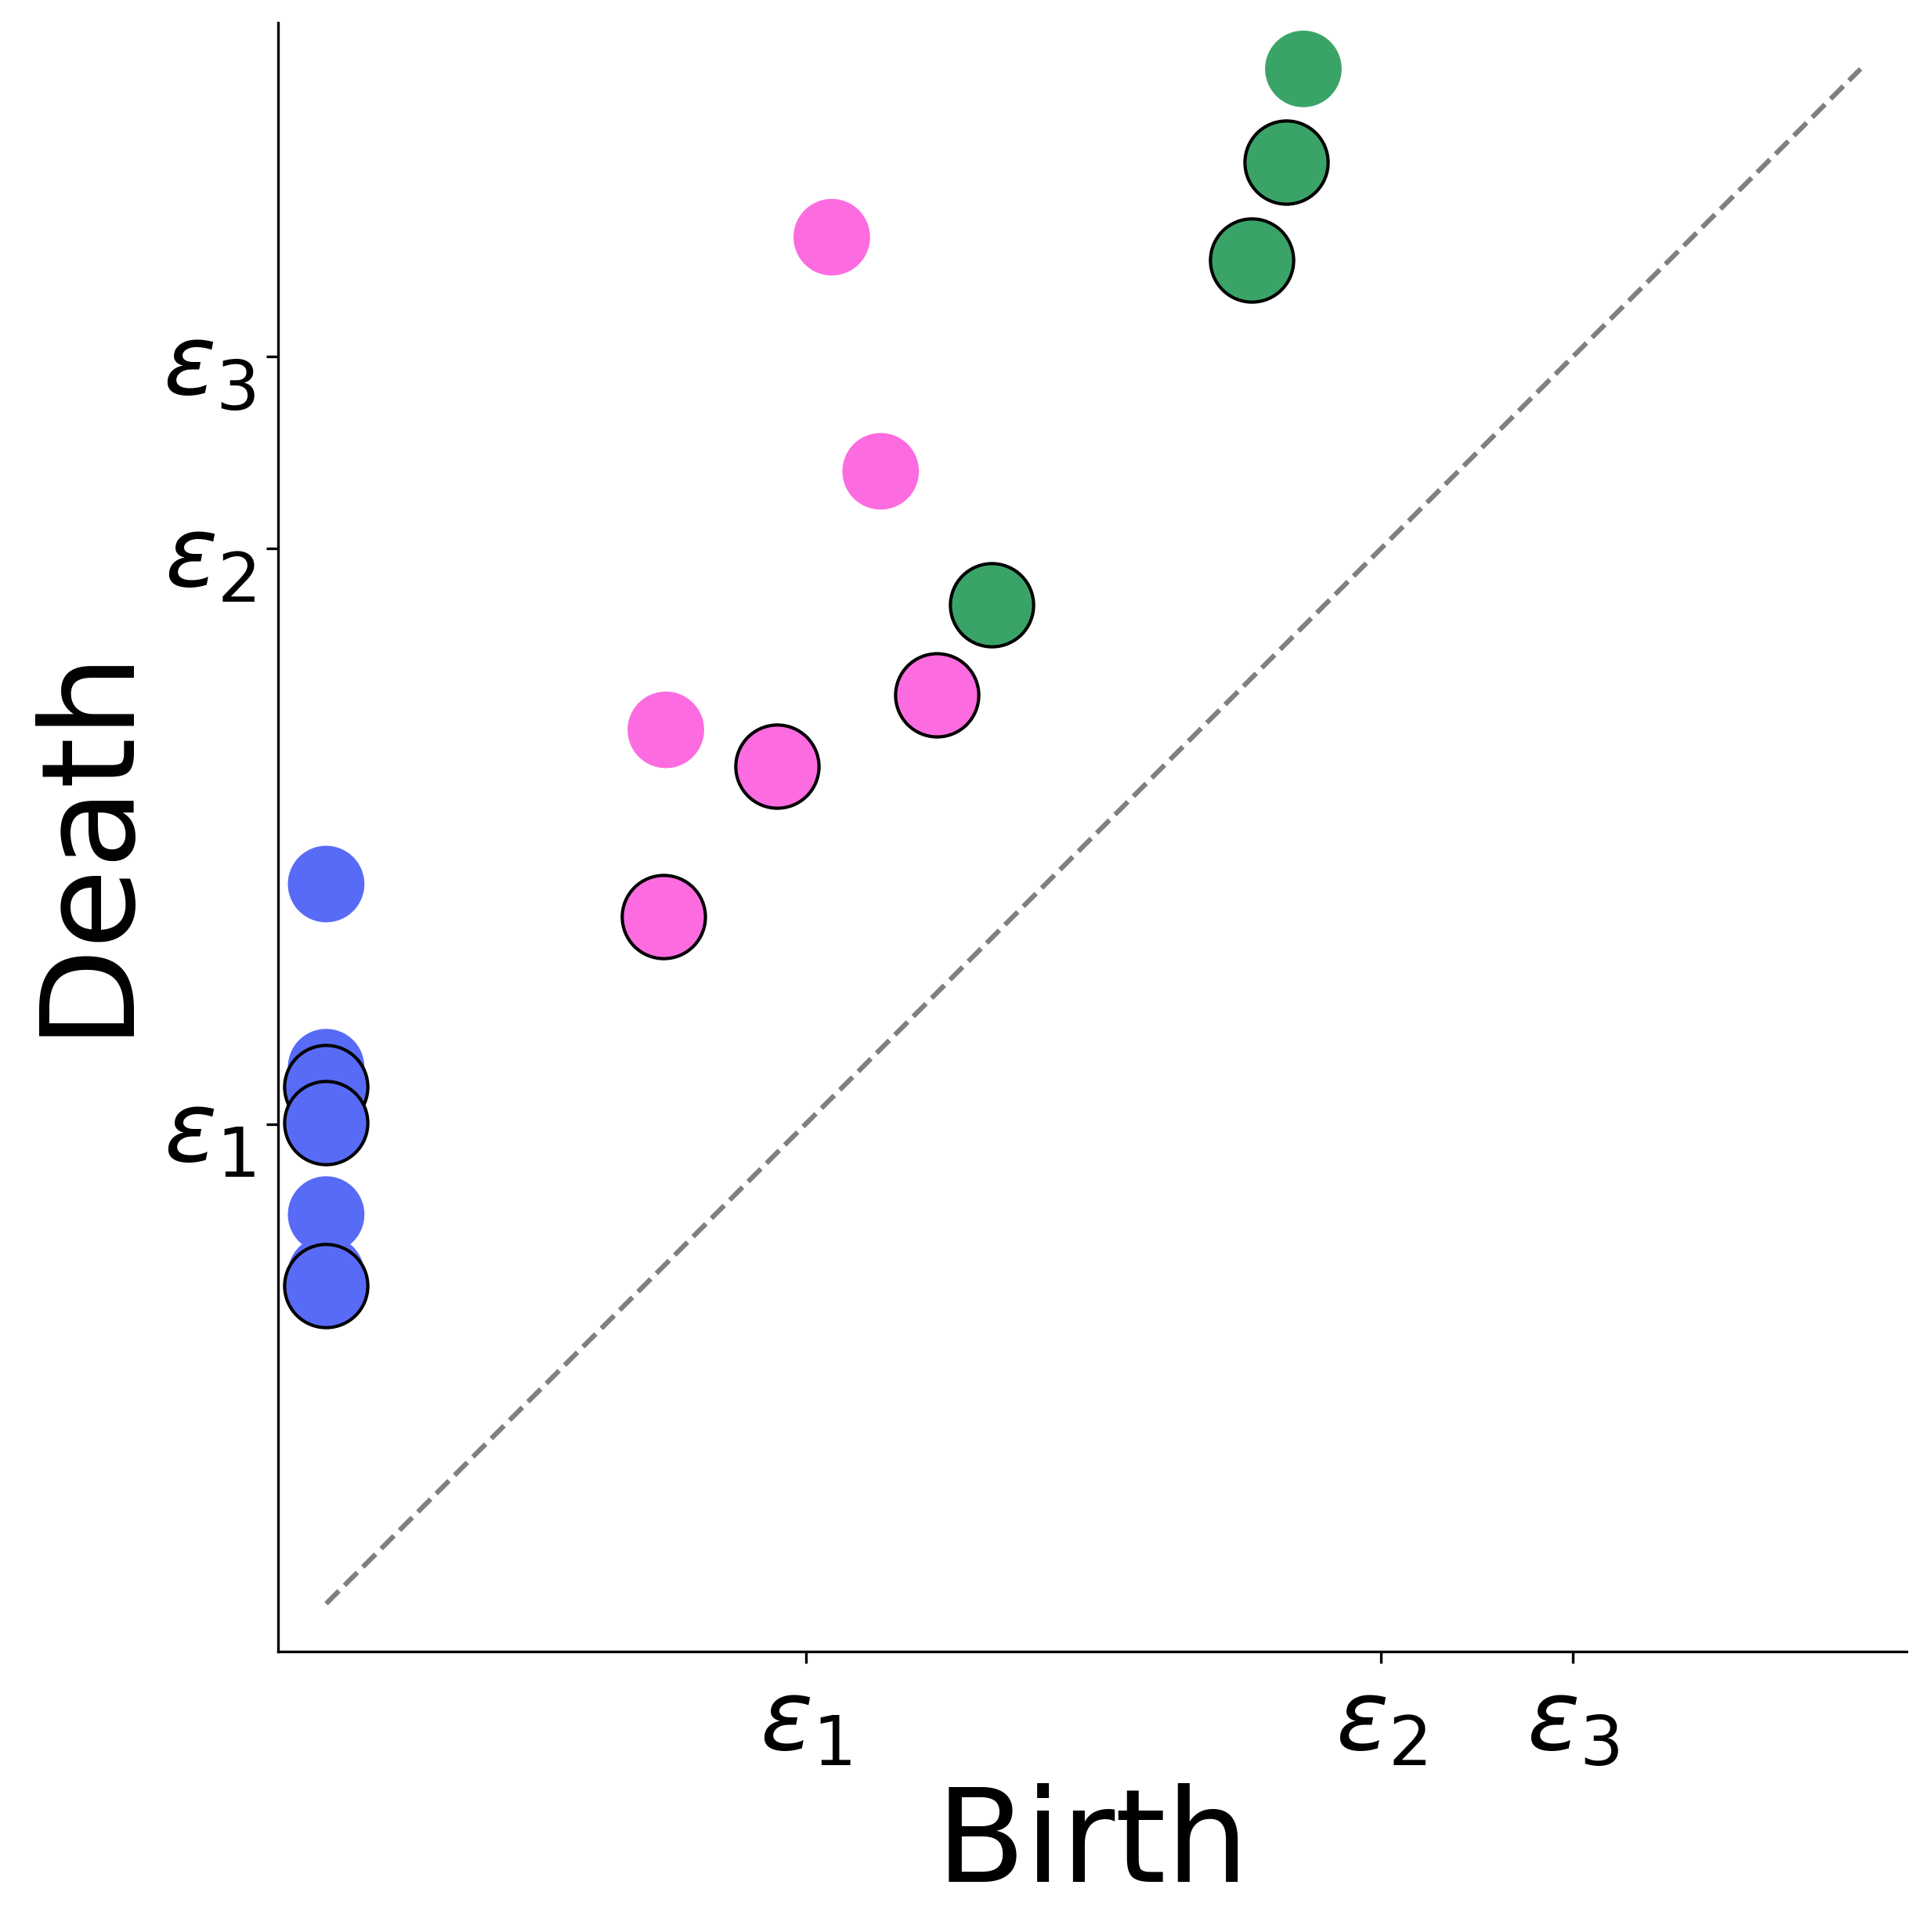

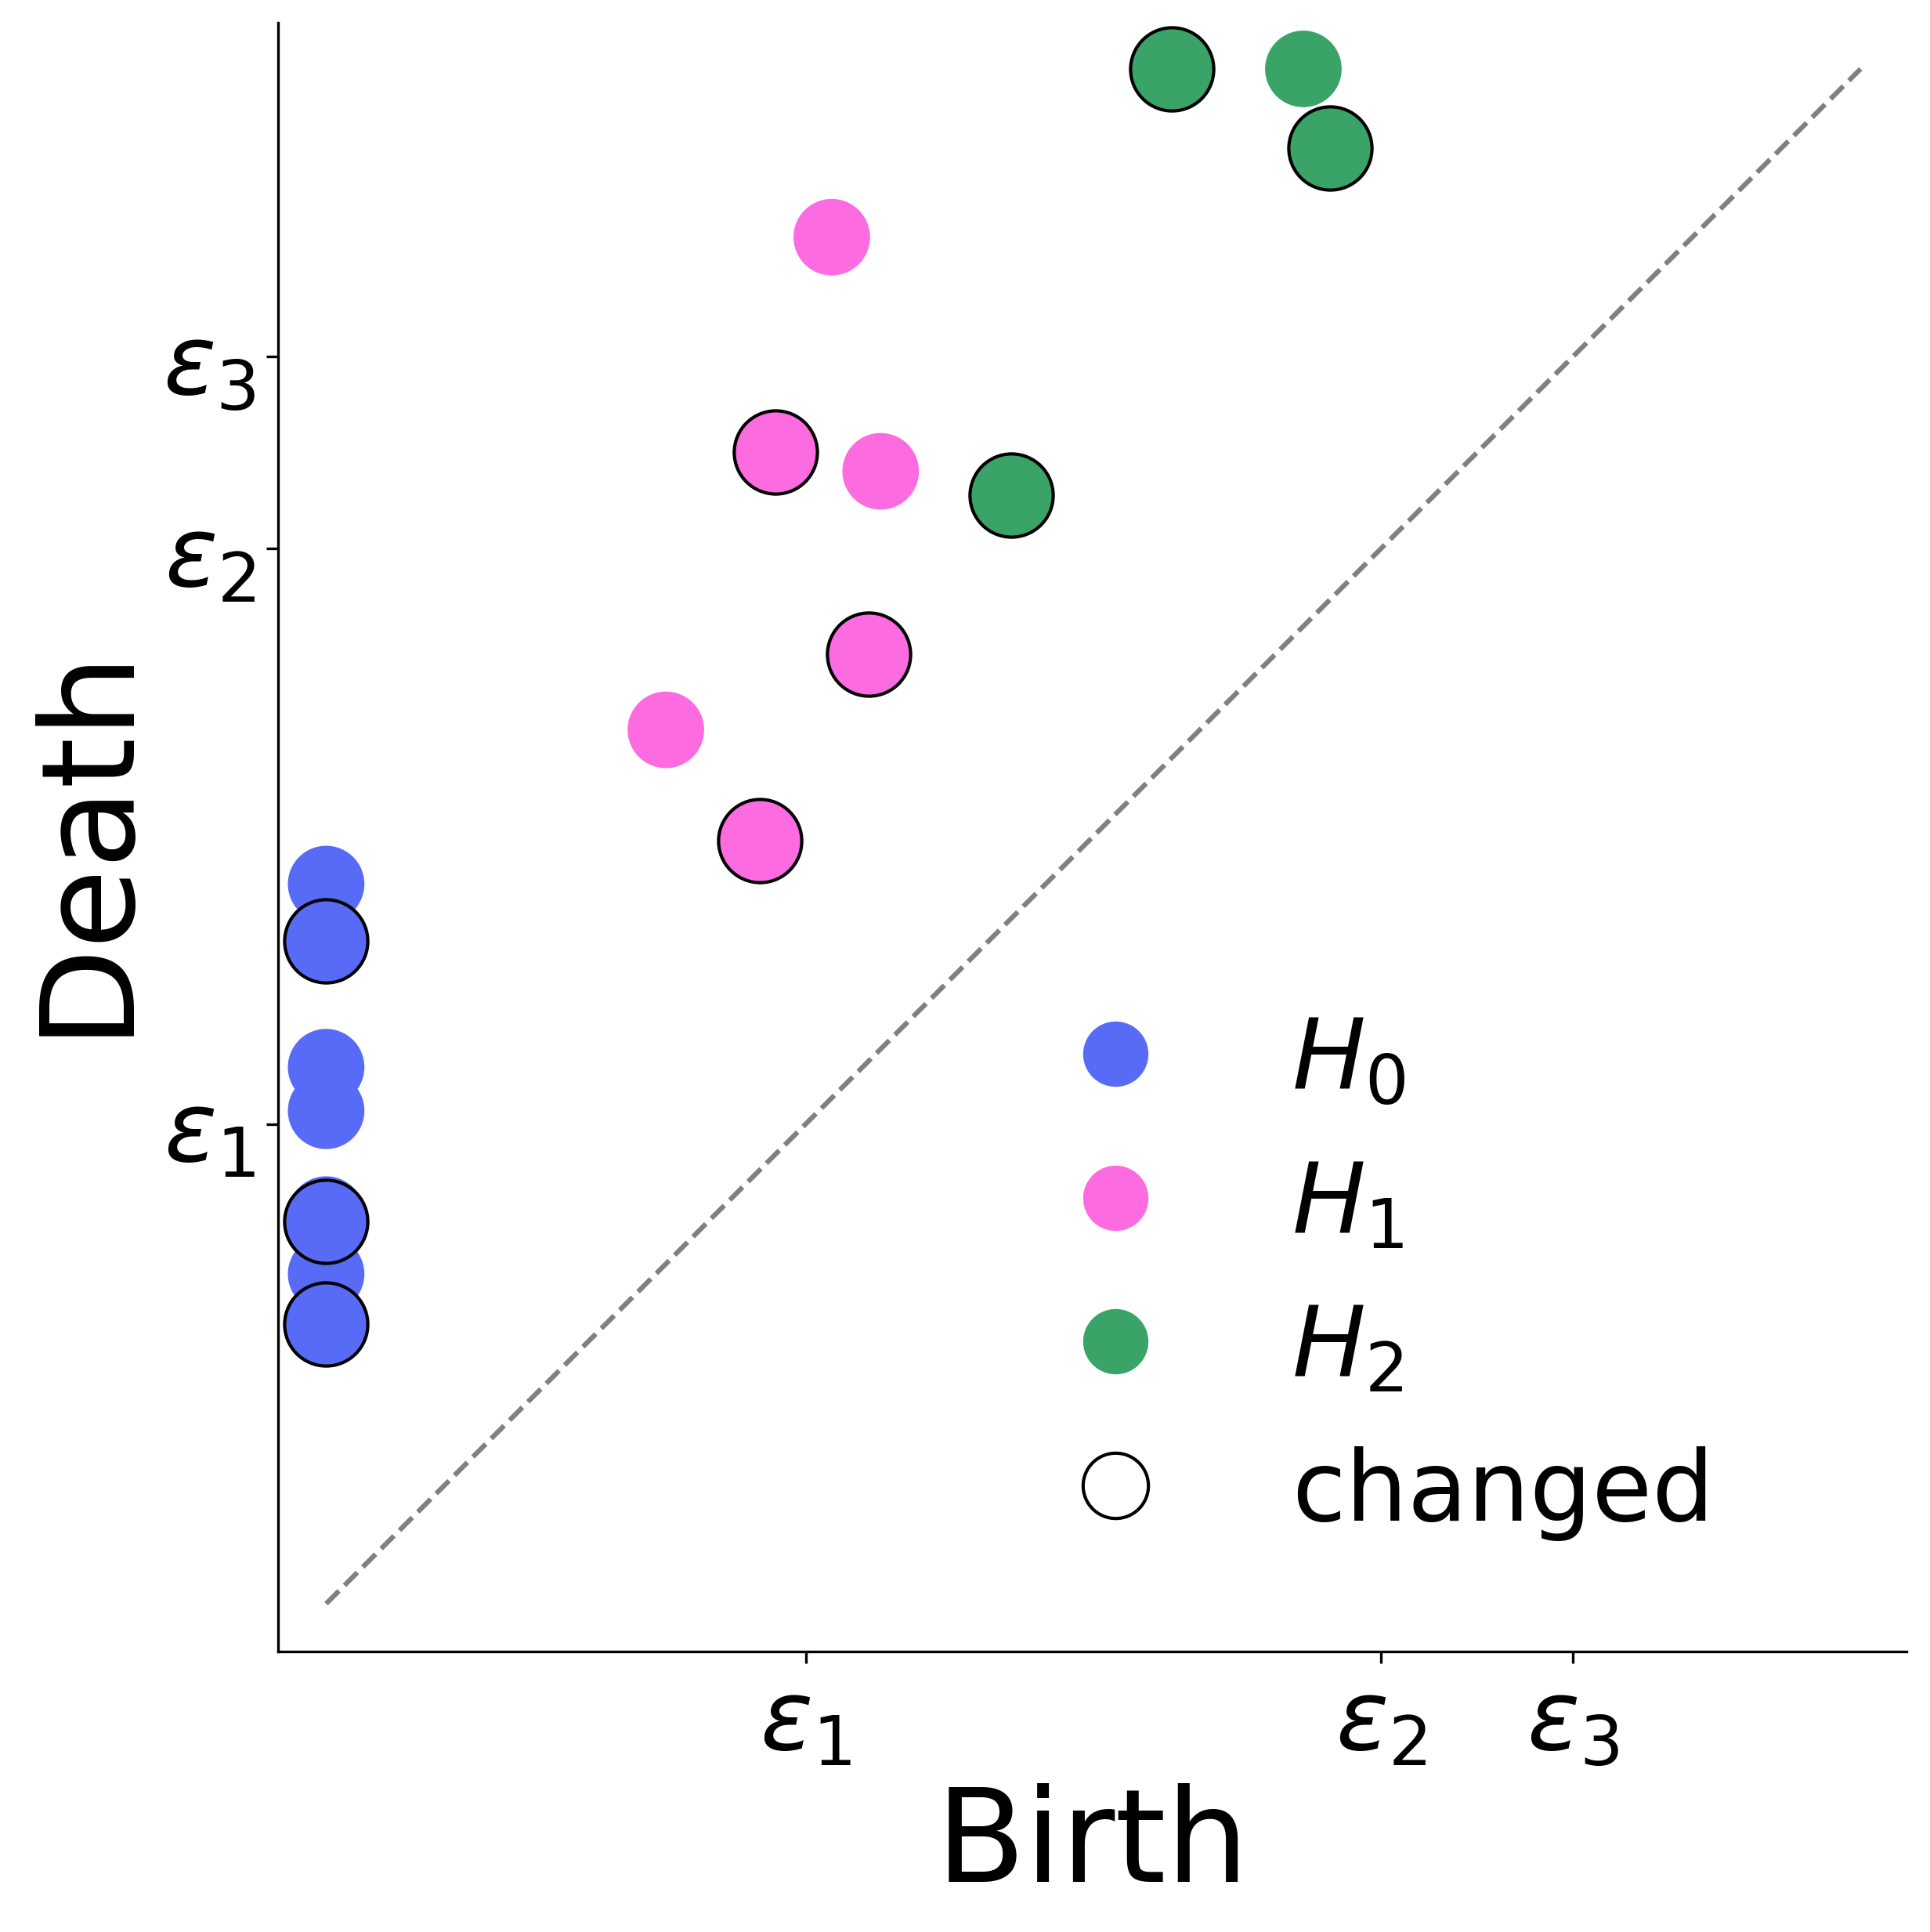

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

rng = np.random.default_rng(7)

homology_palette = {
    "H0": colors_to_use[0],
    "H1": colors_to_use[3],
    "H2": colors_to_use[5],
}

n_points = {"H0": 8, "H1": 6, "H2": 4}

epsilon_values = [0.05, 0.11, 0.13]
epsilon_labels = [r"$\epsilon_1$", r"$\epsilon_2$", r"$\epsilon_3$"]
lim = 0.16

plt.rcParams.update({
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "lines.linewidth": 3,
    "figure.dpi": 300,
})

# --------------------------------------------------
# Generate synthetic persistence diagrams
# --------------------------------------------------

def sample_h(h, n):
    if h == "H0":
        b = np.zeros(n)
        d = np.clip(rng.gamma(1.8, 0.035, n), 0.01, 0.15)

    elif h == "H1":
        b = 0.025 + 0.055 * rng.beta(2.2, 2.8, n)
        lifetime = 0.015 + 0.090 * rng.beta(2.0, 2.0, n)
        d = b + lifetime

    else:
        b = 0.060 + 0.050 * rng.beta(2.5, 2.0, n)
        lifetime = 0.015 + 0.065 * rng.beta(2.0, 2.0, n)
        d = b + lifetime

    return np.c_[b, np.clip(d, b + 0.005, lim)]

base = {
    h: sample_h(h, n_points[h])
    for h in ["H0", "H1", "H2"]
}

# --------------------------------------------------
# Perturb persistence diagram
# --------------------------------------------------

changes = {
    "H0": {"move": 2, "drop": 1, "add": 1, "shift": (0.000, 0.010)},
    "H1": {"move": 2, "drop": 1, "add": 1, "shift": (0.008, 0.012)},
    "H2": {"move": 2, "drop": 1, "add": 1, "shift": (0.008, 0.010)},
}

pert, changed_A, changed_B = {}, {}, {}

for h in ["H0", "H1", "H2"]:
    x = base[h].copy()
    n = len(x)
    c = changes[h]

    idx = rng.permutation(n)
    i_move = idx[:c["move"]]
    i_drop = idx[c["move"]:c["move"] + c["drop"]]

    keep = np.ones(n, dtype=bool)
    keep[i_drop] = False

    moved = x[i_move].copy()

    if h != "H0":
        moved[:, 0] += rng.normal(c["shift"][0], 0.003, len(i_move))

    moved[:, 1] += rng.normal(c["shift"][1], 0.004, len(i_move))

    moved[:, 0] = np.clip(moved[:, 0], 0, lim - 0.005)
    moved[:, 1] = np.clip(
        np.maximum(moved[:, 1], moved[:, 0] + 0.005),
        0,
        lim,
    )

    if h == "H0":
        moved[:, 0] = 0

    y = x[keep]

    map_old_to_new = {
        old: new
        for new, old in enumerate(np.flatnonzero(keep))
    }

    for old, newp in zip(i_move, moved):
        if keep[old]:
            y[map_old_to_new[old]] = newp

    added = sample_h(h, c["add"])

    pert[h] = np.vstack([y, added])

    changed_A[h] = np.sort(np.r_[i_move, i_drop])
    changed_B[h] = np.r_[
        [map_old_to_new[i] for i in i_move if keep[i]],
        np.arange(len(y), len(pert[h]))
    ]

# --------------------------------------------------
# Plot separately
# --------------------------------------------------

axes = []
figs = []

for X, changed in zip([base, pert], [changed_A, changed_B]):

    fig, ax = plt.subplots(figsize=(9, 9))
    figs.append(fig)
    axes.append(ax)

    for h in ["H0", "H1", "H2"]:
        dgm = X[h]

        ax.scatter(
            dgm[:, 0], dgm[:, 1],
            s=550,
            color=homology_palette[h],
            edgecolor="none",
            clip_on=False,
        )

        if len(changed[h]):
            dd = dgm[changed[h]]

            ax.scatter(
                dd[:, 0], dd[:, 1],
                s=650,
                facecolor=homology_palette[h],
                edgecolor="black",
                linewidth=1,
                zorder=10,
                clip_on=False,
            )

    ax.plot(
        [0, lim], [0, lim],
        "--",
        color="grey",
        lw=1.5,
        zorder=0,
    )

    ax.set(
        xlim=(-0.005, lim*1.03),
        ylim=(-0.005, lim*1.03),
        aspect="equal",
    )

    ax.set_xticks(epsilon_values, epsilon_labels)
    ax.set_yticks(epsilon_values, epsilon_labels)

    ax.set_xlabel("Birth", size=40)
    ax.set_ylabel("Death", size=40)
    ax.tick_params(axis="both", labelsize=30)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)

# --------------------------------------------------
# Legend
# --------------------------------------------------

handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=8,
        markerfacecolor=homology_palette[h],
        markeredgecolor="none",
        label=rf"$H_{i}$",
    )
    for i, h in enumerate(["H0", "H1", "H2"])
]

handles += [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=8,
        markerfacecolor="white",
        markeredgecolor="black",
        label="changed",
    )
]

axes[1].legend(
    handles=handles,
    bbox_to_anchor=(0.4, .23),
    loc="center left",
    markerscale=2.5,
    fontsize=30,
    frameon=False,
)

plt.show()

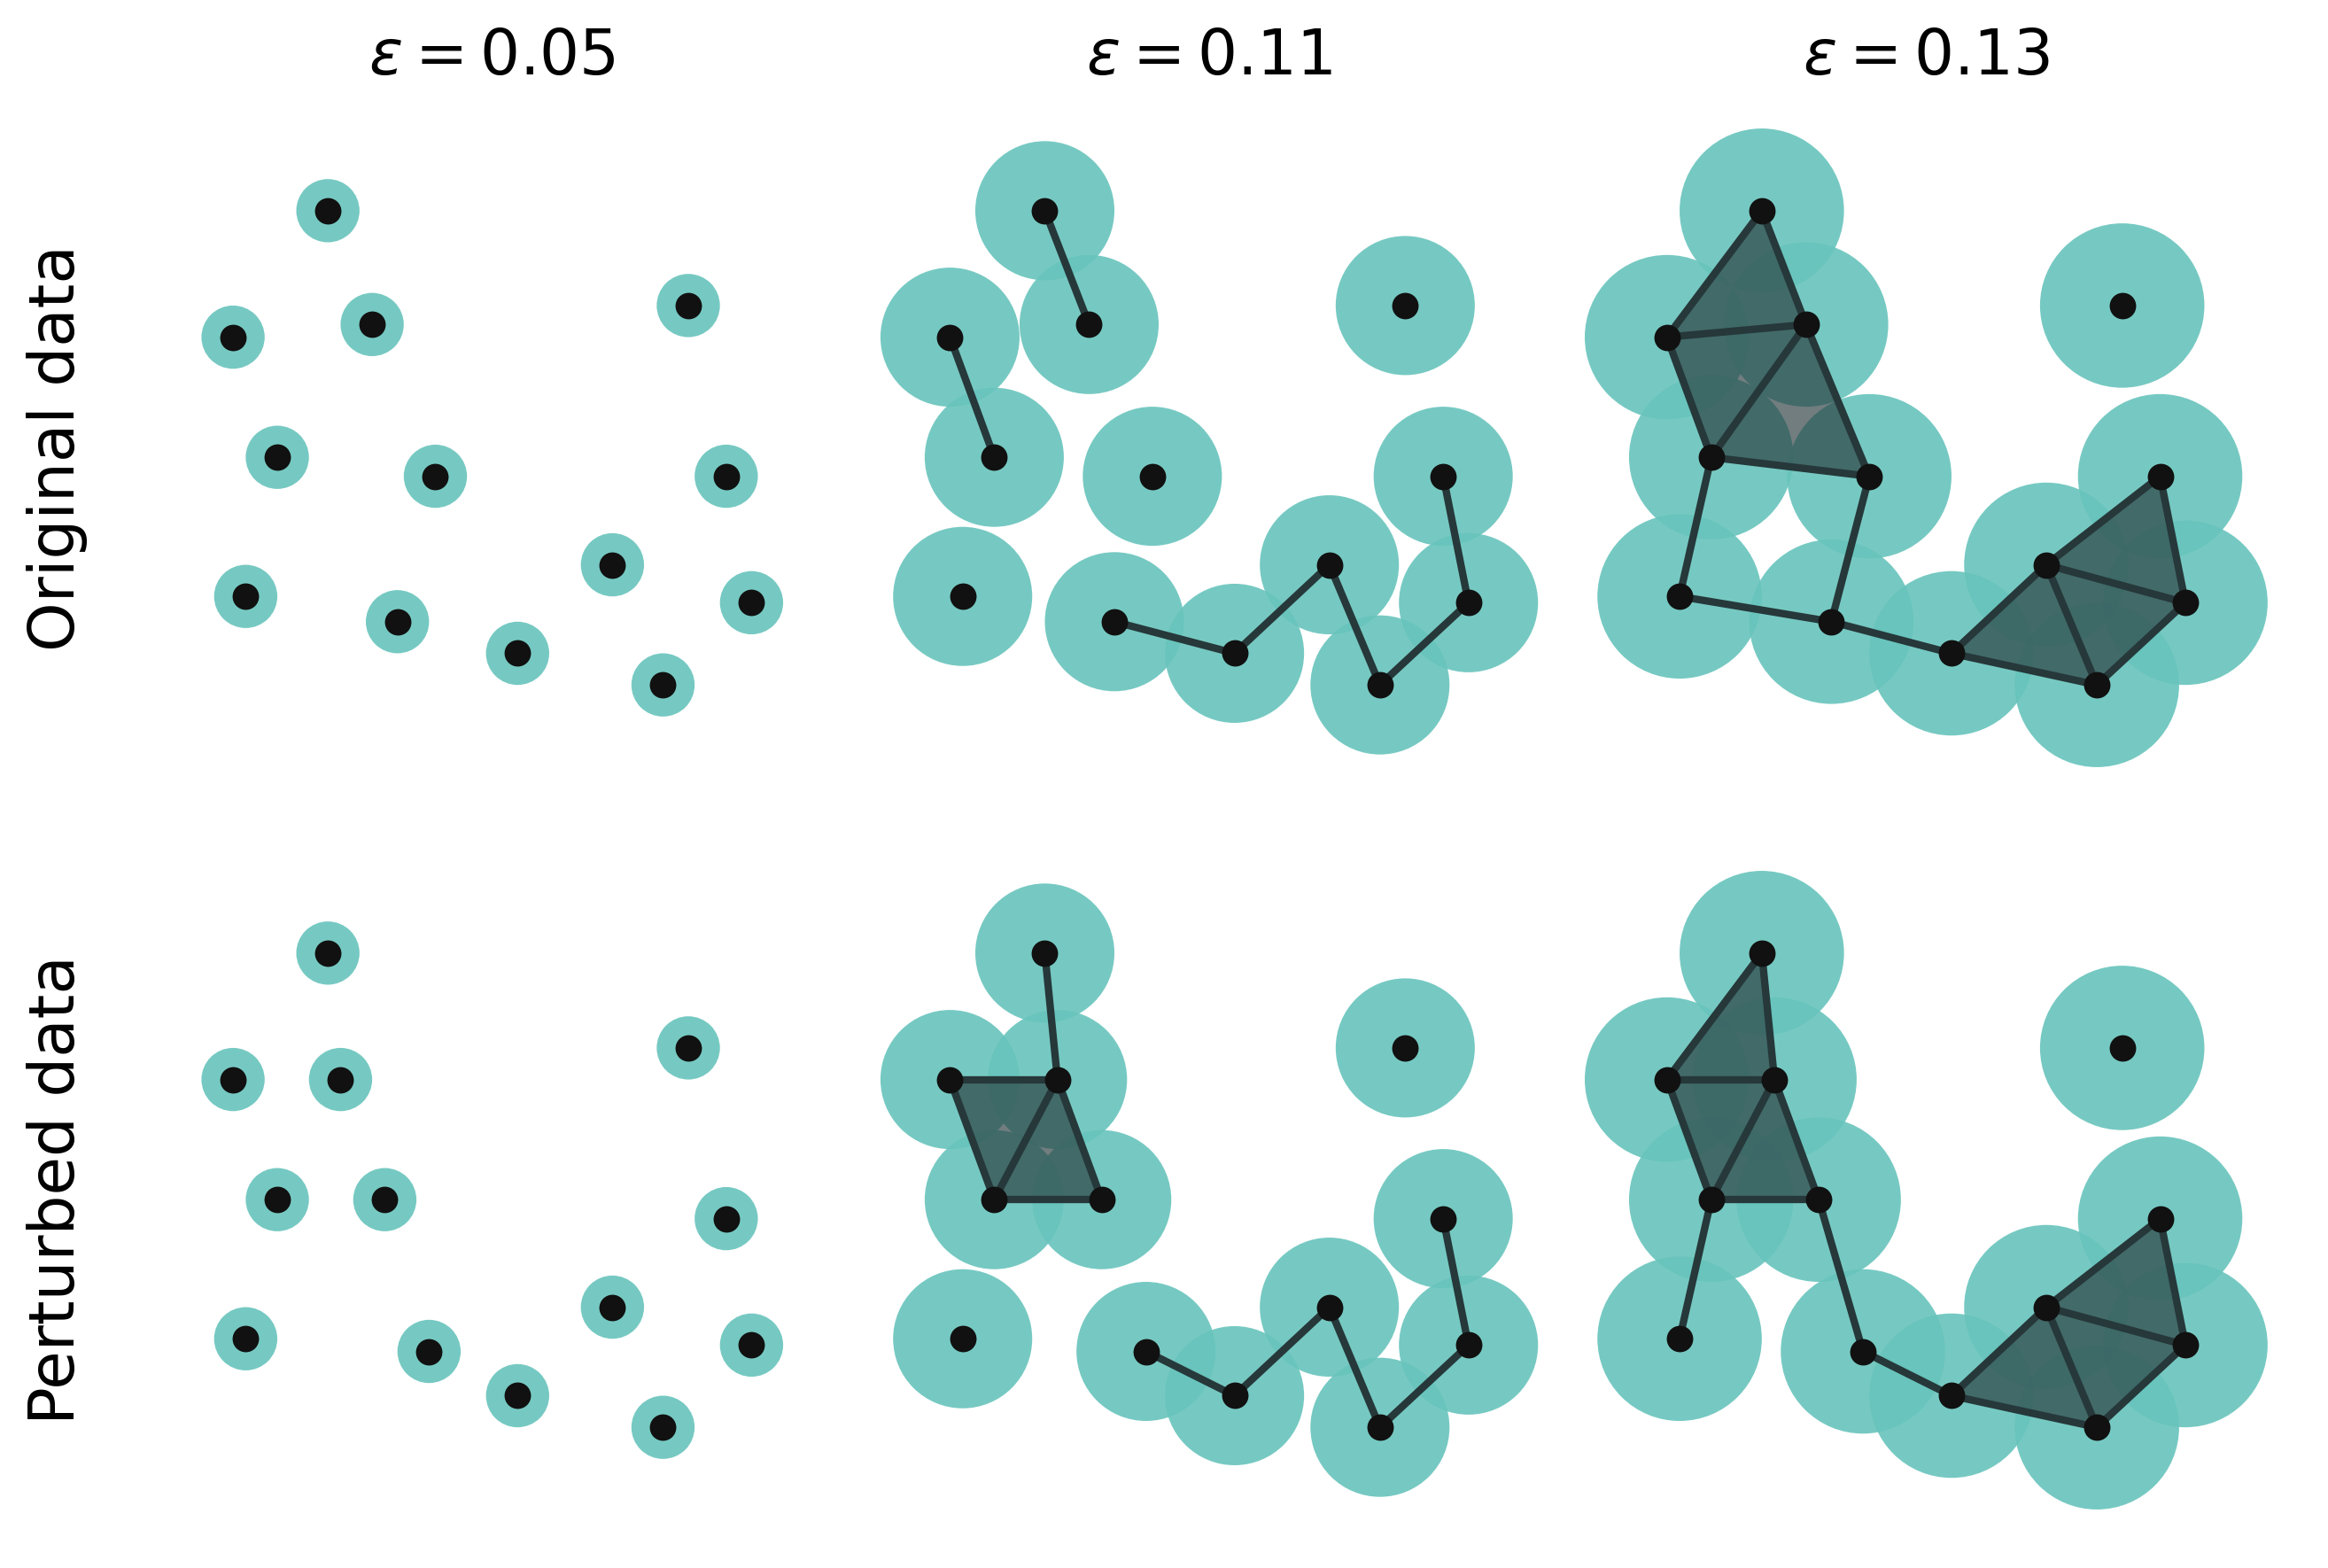

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon
from itertools import combinations

# --------------------------------------------------
# Style
# --------------------------------------------------

ball_color = "#67C4BC"
simplex_color = "#26383A"
point_color = "#111111"

radii = [0.05, 0.11, 0.13]   # 3 filtration values

plt.rcParams.update({"axes.titlesize": 17, "figure.dpi": 300})

# --------------------------------------------------
# Original point cloud
# --------------------------------------------------


points_before = np.array([
    [0.10, 0.70],   # 0
    [0.32, 0.72],   # 1
    [0.17, 0.51],   # 2
    [0.42, 0.48],   # 3
    [0.12, 0.29],   # 4
    [0.36, 0.25],   # 5
  #  [0.62, 0.62],   # 6
    [0.70, 0.34],   # 7
    [0.82, 0.75],   # 8
    [0.88, 0.48],   # 9
    [0.55, 0.20],   # 10
#    [0.52, 0.85],   # 11
    [0.25, 0.90],   # 12
    [0.78, 0.15],   # 13
    [0.92, 0.28],   # 14
])

# --------------------------------------------------
# Perturbed point cloud
# --------------------------------------------------

points_after = points_before.copy()

# Explicit control over which points move:
points_after[1] += [-0.05, -0.02]
points_after[3] += [-0.08,  0.03]
points_after[5] += [ 0.05,  0.02]
#points_after[6] += [-0.06, -0.04]

# --------------------------------------------------
# Vietoris-Rips simplices
# edge appears when distance <= 2r
# --------------------------------------------------

def get_simplices(points, r):
    edges = [
        (i, j)
        for i, j in combinations(range(len(points)), 2)
        if np.linalg.norm(points[i] - points[j]) <= 2*r
    ]

    E = {tuple(sorted(e)) for e in edges}

    triangles = [
        (i, j, k)
        for i, j, k in combinations(range(len(points)), 3)
        if {(i, j), (i, k), (j, k)} <= E
    ]

    return edges, triangles

# --------------------------------------------------
# Draw one filtration value
# --------------------------------------------------

def draw(ax, points, r):
    edges, triangles = get_simplices(points, r)

    # balls
    for p in points:
        ax.add_patch(
            Circle(
                p, r,
                facecolor=ball_color,
                edgecolor="none",
                alpha=.9,
                zorder=0,
            )
        )

    # 2-simplices
    for tri in triangles:
        ax.add_patch(
            Polygon(
                points[list(tri)],
                facecolor=simplex_color,
                edgecolor=simplex_color,
                alpha=.65,
                zorder=1,
            )
        )

    # edges
    for i, j in edges:
        ax.plot(
            points[[i, j], 0],
            points[[i, j], 1],
            color=simplex_color,
            lw=2,
            zorder=2,
        )

    # vertices
    ax.scatter(
        points[:, 0], points[:, 1],
        s=38,
        color=point_color,
        zorder=3,
    )

    # Uncomment while designing to see point IDs
    # for i, (x, y) in enumerate(points):
    #     ax.text(x, y + .025, str(i), ha="center", fontsize=8)

    #ax.set_xlim(-.05, .85)
    #ax.set_ylim(.05, .95)
    ax.set_aspect("equal")
    ax.axis("off")

# --------------------------------------------------
# Plot: 2 × 3 = 6 panels
# --------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True, sharex=True)

for j, r in enumerate(radii):
    draw(axes[0, j], points_before, r)
    draw(axes[1, j], points_after, r)

    axes[0, j].set_title(rf"$\epsilon={r:.2f}$")

axes[0, 0].text(
    -.12, .5, "Original data",
    transform=axes[0, 0].transAxes,
    rotation=90,
    va="center",
    fontsize=17,
)

axes[1, 0].text(
    -.12, .5, "Perturbed data",
    transform=axes[1, 0].transAxes,
    rotation=90,
    va="center",
    fontsize=17,
)

plt.tight_layout(w_pad=-28)
plt.show()

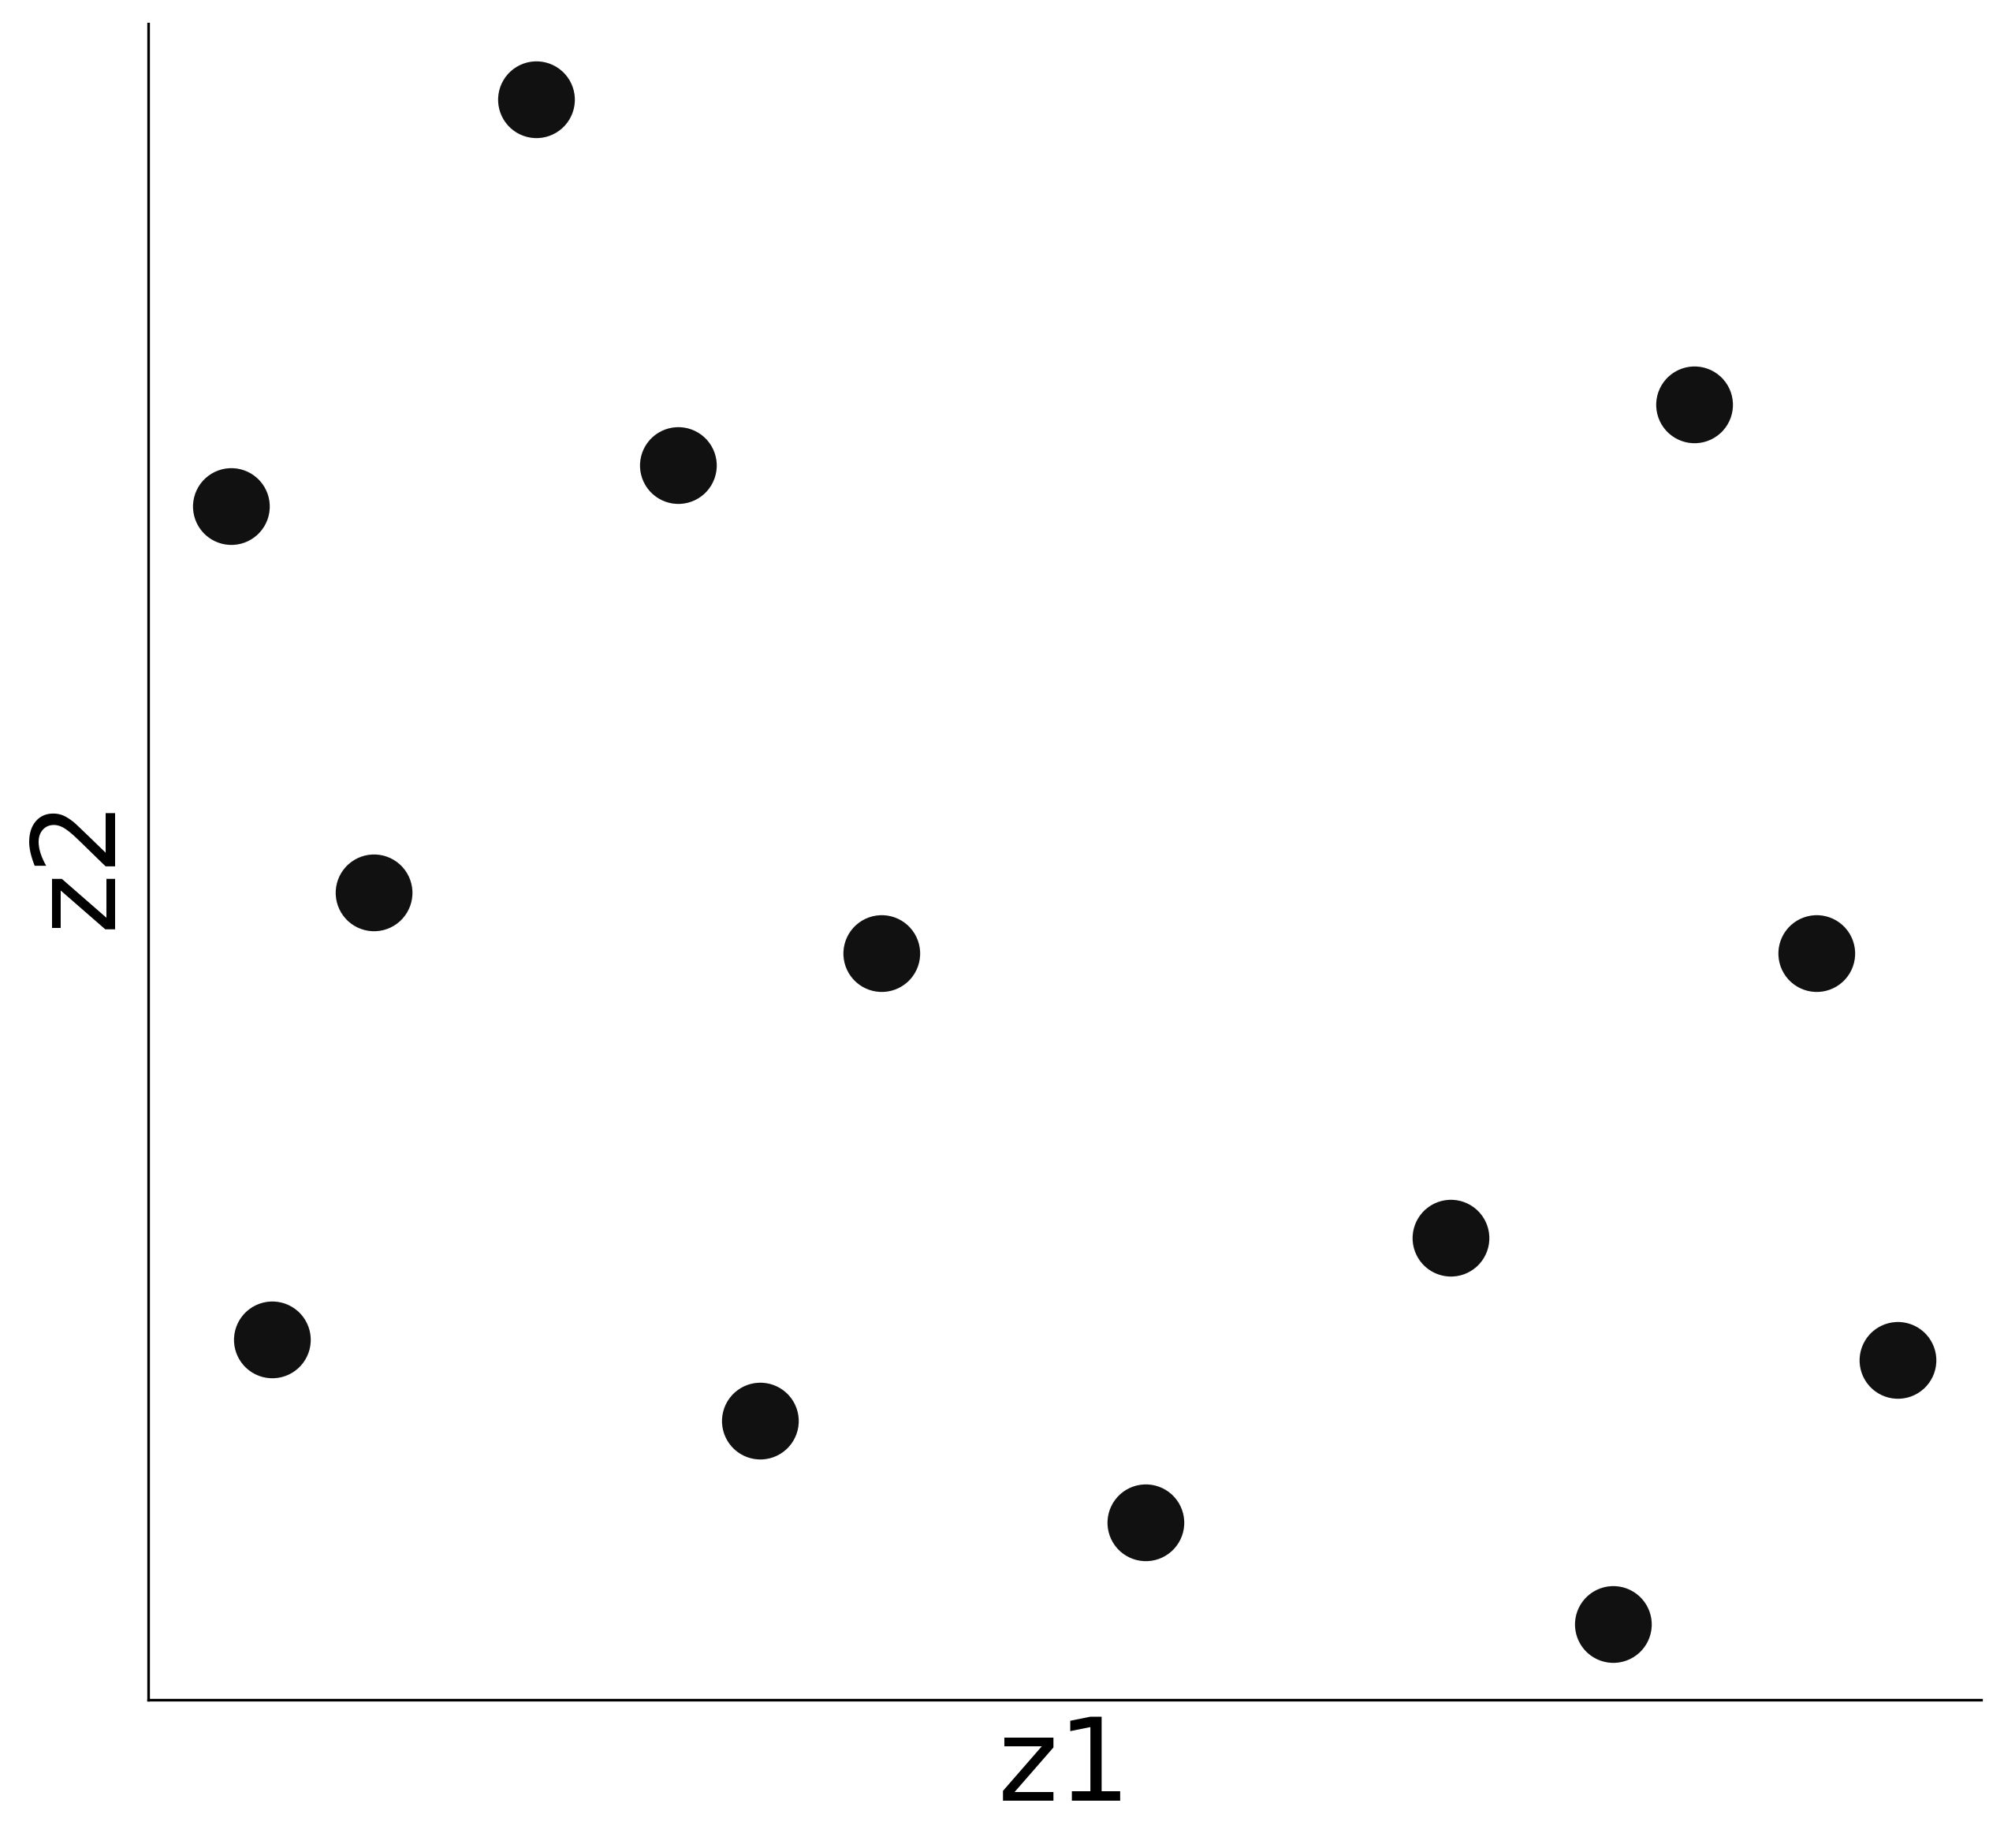

In [54]:
plt.rcParams.update({"axes.titlesize": 17, "figure.dpi": 300})
fig, ax = plt.subplots(1,1, figsize=(10,10))
ax.scatter(
    points_before[:, 0], points_before[:, 1],
    s=500,
    color=point_color,
    zorder=3,
)
ax.set(title="", xticks=[], yticks=[])
ax.set_xlabel("z1", size=35)
ax.set_ylabel("z2", size=35)
ax.set_aspect("equal")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(False)
plt.show()